# Salidas del equipo

## Librerías

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from math import pi

## Carga de datos

In [24]:
ruta_data = Path.cwd().parent.parent / 'data' / 'udlaspalmas'

df_plantilla_2627 = pd.read_csv(ruta_data / 'df_plantilla_2627.csv')
df_individual = pd.read_excel(ruta_data / 'Individual Las Palmas 2526.xlsx')

print(f'Jugadores en plantilla 26/27: {len(df_plantilla_2627)}')
print(f'Registros individuales 25/26: {len(df_individual)}')

Jugadores en plantilla 26/27: 22
Registros individuales 25/26: 27


## Ver qué jugadores no continuan en el club

In [ ]:
# Creación del DF: 'Nombre Métrica' : 'Nombre Plantilla'
diccionario_nombres = {
    'Mika Mármol': 'Mika Mármol',
    'Kirian Rodríguez': 'Kirian Rodríguez',
    'E. Loiodice': 'Enzo Loiodice',
    'N. Benedetti': 'Nicolás Benedetti',
    'Manu Fuster': 'Manu Fuster',
    'Marvin Park': 'Marvin Park',
    'José Antonio Caro': 'José Antonio Caro',
    'Pejiño': 'Pejiño',
    'Cristian Gutiérrez': 'Cristian Gutiérrez',
    'Álex Suárez': 'Álex Suárez',
    'D. Horkaš': 'Dinko Horkas',
    'Sergio Barcia': 'Sergio Barcia',
    'Iván Gil': 'Iván Gil',
    'Jonathan Viera': 'Jonathan Viera',
    'T. Miyashiro': 'Taisei Miyashiro',
    'Jesé Rodríguez': 'Jesé',
    'Iker Bravo': 'Iker Bravo',
    'Enrique Clemente': 'Enrique Clemente',
    'Ale García': 'Ale García',
    'Sandro Ramírez': 'Sandro Ramírez',
    'Viti Rozada': 'Viti Rozada',
    'J. Recoba': 'Jeremía Recoba',
    'Juanma Herzog': 'Juanma Herzog',
    'Adrian Suarez': 'Adri Suárez',
    'Estanis Pedrola': 'Estanis Pedrola',
    'Iñaki González': 'Iñaki González',
    'L. Amatucci': 'Lorenzo Amatucci'
}

In [25]:
def identificar_bajas(df_individual, df_plantilla_2627, diccionario_nombres):
    """
    Cruza los datos individuales de Wyscout con la plantilla 26/27 para identificar
    qué jugadores no continuarán y qué estadísticas deja de aportar el equipo.
    """
    df = df_individual.copy()
    df['Jugador_Unificado'] = df['Player'].map(diccionario_nombres)

    jugadores_que_siguen = df_plantilla_2627['Jugador'].tolist()
    df_bajas = df[~df['Jugador_Unificado'].isin(jugadores_que_siguen)].copy()

    # Etiquetar el DataFrame completo para diferenciarlo en los gráficos
    df['Estatus'] = df['Jugador_Unificado'].apply(
        lambda x: 'Causa Baja' if x not in jugadores_que_siguen else 'Se Queda'
    )

    return df_bajas.reset_index(drop=True), df


df_bajas, df_individual_etiquetado = identificar_bajas(
    df_individual, df_plantilla_2627, diccionario_nombres
)

print(f'Total de bajas identificadas: {len(df_bajas)}')
print('\nJugadores que no continuarán:')
print(df_bajas['Player'].to_string(index=False))

Total de bajas identificadas: 8

Jugadores que no continuarán:
    Mika Mármol
   N. Benedetti
         Pejiño
  Sergio Barcia
 Jonathan Viera
     Iker Bravo
Estanis Pedrola
    L. Amatucci


## Volumen perdida

In [ ]:
# Métricas que se evaluan para ver cúanto se pierde
METRICAS_ABSOLUTAS = ['Minutes played', 'Goals', 'xG', 'Assists', 'xA']

METRICAS_P90 = [
    'Progressive runs per 90',
    'Passes to final third per 90',
    'Interceptions per 90',
    'Defensive duels per 90'
]

In [27]:
def calcular_volumen_total(df, metricas_absolutas, metricas_p90):
    """
    Convierte métricas por 90 a volumen total y suma el resultado del grupo.
    Se usa tanto para el equipo completo como para el subconjunto de bajas.
    """
    df_calc = df.fillna(0).copy()

    for col in metricas_p90:
        nombre_total = col.replace(' per 90', ' (Total)')
        df_calc[nombre_total] = (df_calc[col] * df_calc['Minutes played']) / 90

    cols_volumen = metricas_absolutas + [m.replace(' per 90', ' (Total)') for m in metricas_p90]
    return df_calc[cols_volumen].sum()


def calcular_impacto_bajas(df_equipo, df_bajas, metricas_absolutas, metricas_p90):
    """Construye la tabla de impacto comparando el volumen del equipo con las bajas."""
    volumen_equipo = calcular_volumen_total(df_equipo, metricas_absolutas, metricas_p90)
    volumen_bajas = calcular_volumen_total(df_bajas, metricas_absolutas, metricas_p90)

    df_impacto = pd.DataFrame({
        'Total Equipo': volumen_equipo,
        'Pérdida Absoluta': volumen_bajas
    })
    df_impacto['% Perdido'] = (df_impacto['Pérdida Absoluta'] / df_impacto['Total Equipo'] * 100).round(2)
    df_impacto['% Se Queda'] = (100 - df_impacto['% Perdido']).round(2)

    return df_impacto


df_impacto = calcular_impacto_bajas(df_individual, df_bajas, METRICAS_ABSOLUTAS, METRICAS_P90)
print(df_impacto[['Total Equipo', 'Pérdida Absoluta', '% Perdido']].to_string())

                               Total Equipo  Pérdida Absoluta  % Perdido
Minutes played                 51006.000000      17056.000000      33.44
Goals                             69.000000         16.000000      23.19
xG                                63.970000         20.780000      32.48
Assists                           50.000000         15.000000      30.00
xA                                33.080000         10.810000      32.68
Progressive runs (Total)         812.570556        321.239000      39.53
Passes to final third (Total)   2389.906667        983.674111      41.16
Interceptions (Total)           1662.358444        673.803889      40.53
Defensive duels (Total)         2525.740556        995.382000      39.41


## Visualización del impacto

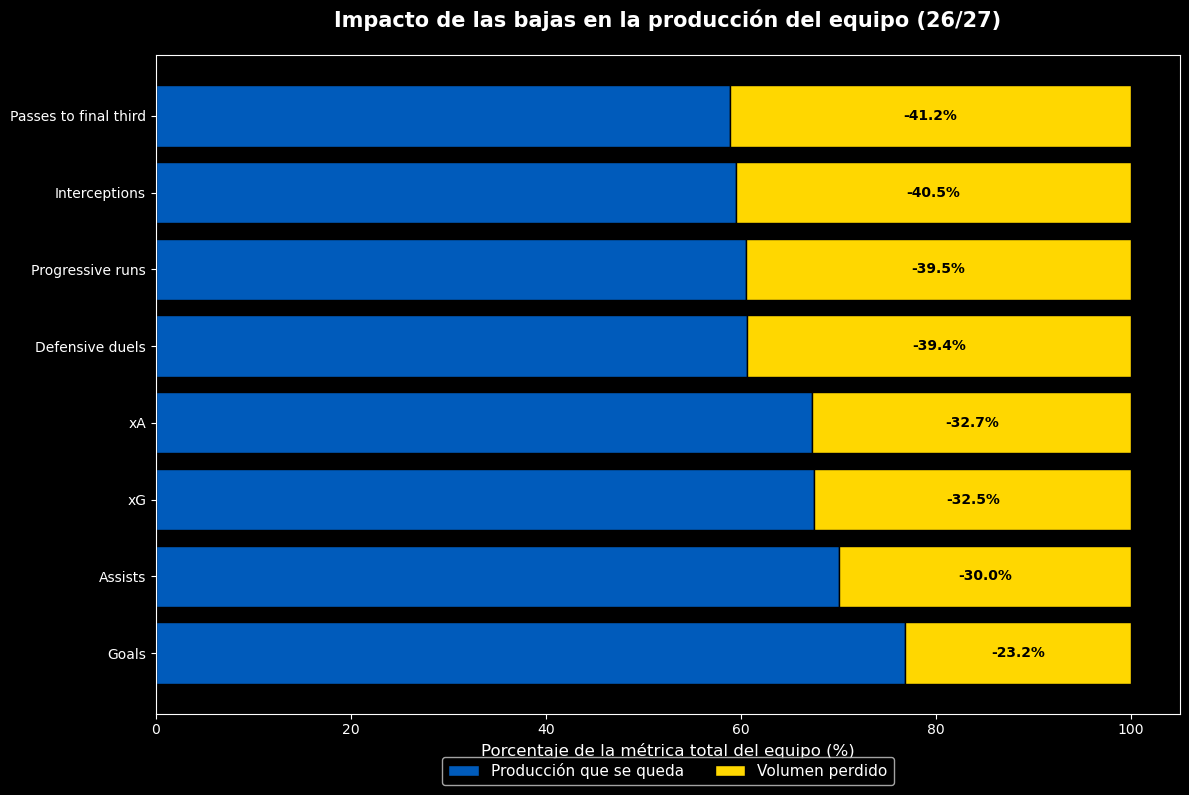

In [28]:
def graficar_impacto_barras(df_impacto):
    """Barras apiladas horizontales con el porcentaje perdido por métrica."""
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(12, 8))

    # Excluir minutos para que el gráfico se centre en métricas de juego
    df_plot = df_impacto.drop('Minutes played').sort_values('% Perdido', ascending=True)
    etiquetas = df_plot.index.str.replace(' (Total)', '', regex=False)
    perdido = df_plot['% Perdido']
    se_queda = df_plot['% Se Queda']

    ax.barh(etiquetas, se_queda, color='#005BBB', edgecolor='black', label='Producción que se queda')
    ax.barh(etiquetas, perdido, left=se_queda, color='#FFD700', edgecolor='black', label='Volumen perdido')

    for i, (q, p) in enumerate(zip(se_queda, perdido)):
        if p > 5:
            ax.text(q + p / 2, i, f'-{p:.1f}%', ha='center', va='center',
                    color='black', fontweight='bold', fontsize=10)

    ax.set_title('Impacto de las bajas en la producción del equipo (26/27)',
                 fontsize=15, fontweight='bold', pad=20)
    ax.set_xlabel('Porcentaje de la métrica total del equipo (%)', fontsize=12)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=11)
    plt.tight_layout()
    plt.show()


graficar_impacto_barras(df_impacto)

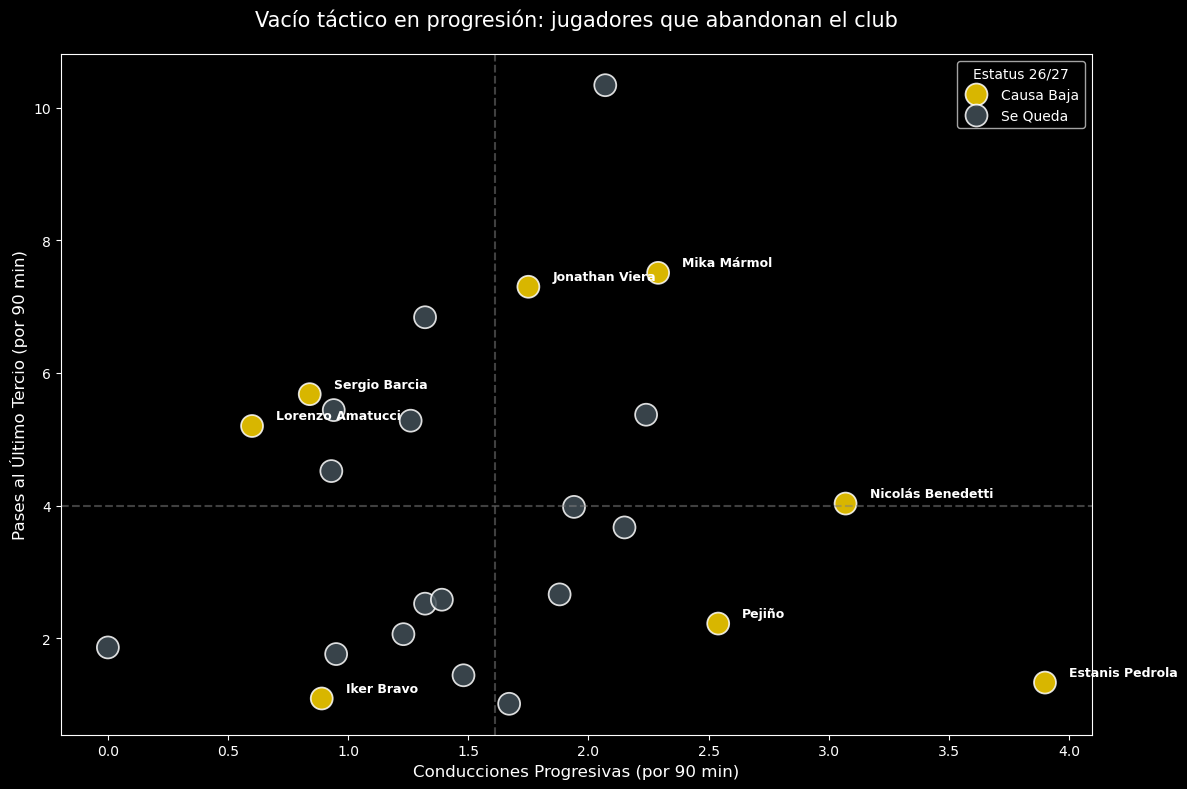

In [29]:
def graficar_vacio_tactico(df_etiquetado):
    """Scatter de progresión vs pases al último tercio para revelar el vacío táctico."""
    plt.style.use('dark_background')
    plt.figure(figsize=(12, 8))

    sns.scatterplot(
        data=df_etiquetado,
        x='Progressive runs per 90',
        y='Passes to final third per 90',
        hue='Estatus',
        palette={'Se Queda': '#435058', 'Causa Baja': '#FFD700'},
        s=250, alpha=0.85, edgecolor='white'
    )

    for _, fila in df_etiquetado[df_etiquetado['Estatus'] == 'Causa Baja'].iterrows():
        plt.text(
            fila['Progressive runs per 90'] + 0.1,
            fila['Passes to final third per 90'] + 0.1,
            fila['Jugador_Unificado'],
            fontsize=9, color='white', fontweight='bold'
        )

    media_x = df_etiquetado['Progressive runs per 90'].mean()
    media_y = df_etiquetado['Passes to final third per 90'].mean()
    plt.axvline(x=media_x, color='gray', linestyle='--', alpha=0.5)
    plt.axhline(y=media_y, color='gray', linestyle='--', alpha=0.5)

    plt.title('Vacío táctico en progresión: jugadores que abandonan el club',
              fontsize=15, pad=20)
    plt.xlabel('Conducciones Progresivas (por 90 min)', fontsize=12)
    plt.ylabel('Pases al Último Tercio (por 90 min)', fontsize=12)
    plt.legend(title='Estatus 26/27')
    plt.tight_layout()
    plt.show()


graficar_vacio_tactico(df_individual_etiquetado)

#### Análisis de perfil por posición

In [30]:
def analizar_perfil_posicion(df_etiquetado, filtro_posicion, metricas_radar, titulo):
    """
    Genera un radar comparando el perfil medio de los que se van vs los que se quedan
    para una posición concreta. Acepta cualquier posición, no solo centrales.
    """
    df_pos = df_etiquetado[df_etiquetado['Position'].str.contains(filtro_posicion, na=False)]

    if df_pos.empty:
        print(f'No hay jugadores con filtro: {filtro_posicion}')
        return

    perfil_bajas = df_pos[df_pos['Estatus'] == 'Causa Baja'][metricas_radar].mean()
    perfil_quedan = df_pos[df_pos['Estatus'] == 'Se Queda'][metricas_radar].mean()

    # Preparar el radar cerrando el polígono
    vals_bajas = perfil_bajas.values.tolist() + perfil_bajas.values[:1].tolist()
    vals_quedan = perfil_quedan.values.tolist() + perfil_quedan.values[:1].tolist()
    angulos = [n / float(len(metricas_radar)) * 2 * pi for n in range(len(metricas_radar))]
    angulos += angulos[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True),
                           facecolor='#1A1A2E')
    ax.set_facecolor('#1A1A2E')

    plt.xticks(angulos[:-1], metricas_radar, color='white', size=9)
    ax.set_rlabel_position(0)
    plt.yticks(color='gray', size=8)
    limite = max(max(vals_bajas), max(vals_quedan)) * 1.15
    plt.ylim(0, limite)

    ax.plot(angulos, vals_bajas, linewidth=2, color='#FFD700', label='Se van')
    ax.fill(angulos, vals_bajas, color='#FFD700', alpha=0.2)
    ax.plot(angulos, vals_quedan, linewidth=2, color='#005BBB', label='Se quedan')
    ax.fill(angulos, vals_quedan, color='#005BBB', alpha=0.2)

    plt.title(titulo, size=13, color='white', y=1.12, fontweight='bold')
    plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15))
    plt.tight_layout()
    plt.show()

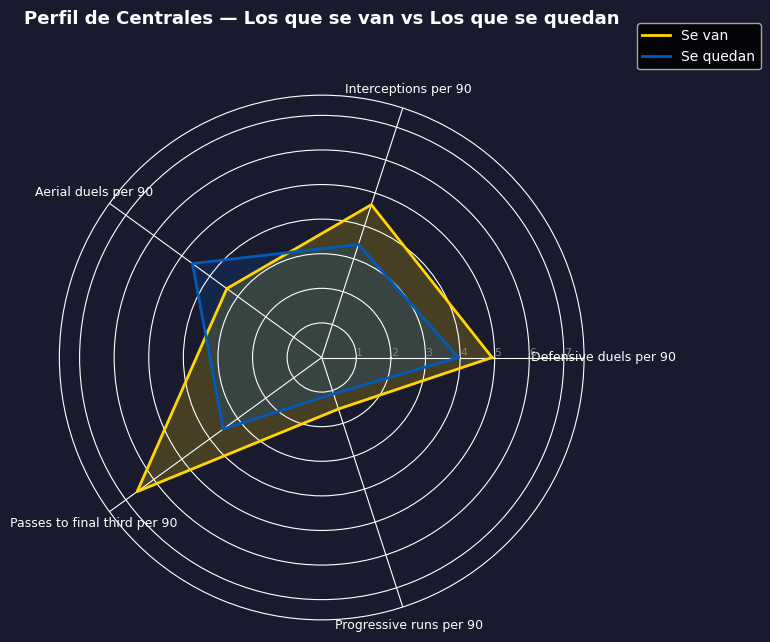

In [31]:
metricas_defensa = [
    'Defensive duels per 90',
    'Interceptions per 90',
    'Aerial duels per 90',
    'Passes to final third per 90',
    'Progressive runs per 90'
]

analizar_perfil_posicion(
    df_individual_etiquetado,
    filtro_posicion='CB',
    metricas_radar=metricas_defensa,
    titulo='Perfil de Centrales — Los que se van vs Los que se quedan'
)

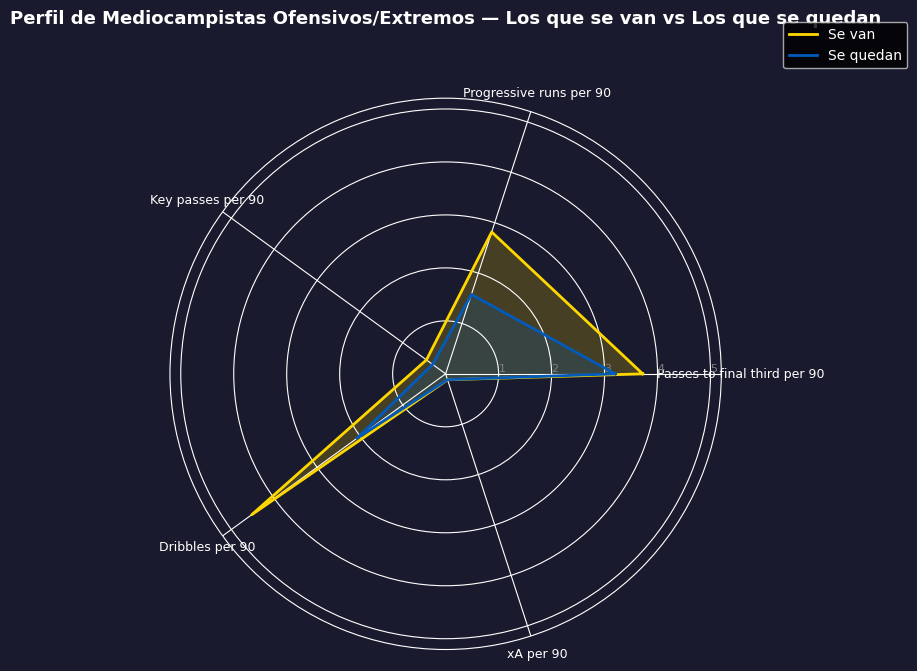

In [ ]:
# Métricas para mediocentro ofensivos, fijarse que las métricas no son las mismas para evaluar
metricas_medio_ofensivo = [
    'Passes to final third per 90',
    'Progressive runs per 90',
    'Key passes per 90',
    'Dribbles per 90',
    'xA per 90'
]

analizar_perfil_posicion(
    df_individual_etiquetado,
    filtro_posicion='AMF|RW|LW',
    metricas_radar=metricas_medio_ofensivo,
    titulo='Perfil de mediocampistas ofensivos/extremos — Los que se van vs Los que se quedan'
)

## Exportar resultados

In [33]:
def guardar_resultados_bajas(df_bajas, df_impacto, ruta_destino):
    """Exporta los dos DataFrames clave para que los use el notebook de captaciones."""
    ruta = Path(ruta_destino)
    ruta.mkdir(parents=True, exist_ok=True)

    df_bajas.to_csv(ruta / 'df_bajas_2627.csv', index=False, encoding='utf-8-sig')
    df_impacto.to_csv(ruta / 'df_impacto_bajas.csv', encoding='utf-8-sig')

    print('Exportados:')
    print(f'  - df_bajas_2627.csv ({len(df_bajas)} filas)')
    print(f'  - df_impacto_bajas.csv ({len(df_impacto)} métricas)')


guardar_resultados_bajas(df_bajas, df_impacto, ruta_data)

Exportados:
  - df_bajas_2627.csv (8 filas)
  - df_impacto_bajas.csv (9 métricas)
